# 06 — Computational burden

**Project:** Design and Evaluation of a Governed Multi-Signal Drift-Aware Intervention Policy under Delayed Labels: A Google Cloud MLOps Prototype  

**Author:** Sahar Imani  

Computes the computational-burden results from the exported files in `computational_burden/inputs/`.

1. Input inventory and burden definitions
2. Observed offline candidate-fitting workload
3. Policy A\* counterfactual workload
4. Workload comparison across A, A\*, B, C and D
5. Measured Policy C Google Cloud replay workload
6. Challenger training rows against measured fit runtime
7. Modelled runtime for Policy B and Policy A\*
8. Dissertation and Appendix H output tables
9. Audit and claim boundaries

No monetary cost is reported: the evidence bundle contains no validated Cloud Billing export.

In [1]:
# required set up
import json
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import computational_burden_analysis as cba

BASE = Path.cwd()
INPUTS = BASE / "inputs"
OFFLINE = INPUTS / "offline"
GCP = INPUTS / "gcp"
OUTPUTS = BASE / "outputs"
OUTPUTS.mkdir(exist_ok=True)

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

In [2]:
# Audit checks
AUDIT_CHECKS = []

def check(name, computed, expected, tolerance=0.0, note=""):
    if isinstance(expected, (int, float)) and isinstance(computed, (int, float)):
        passed = abs(float(computed) - float(expected)) <= tolerance
    else:
        passed = computed == expected
    AUDIT_CHECKS.append({"check": name, "computed": computed, "expected": expected, "tolerance": tolerance, "passed": bool(passed), "note": note})
    if not passed:
        print(f"CHECK FAILED  {name}: computed={computed!r} expected={expected!r} tol={tolerance}")
    return passed

## 1. Input inventory and burden definitions

21 exported files: 13 from the offline experiment and 8 from the Google Cloud replay. The inventory check runs first so the analysis stops if anything is missing.

Study settings come from `final_policy_metadata.json`. The five-month label delay is a simulation assumption, not Lending Club's true label-maturity timing.

In [3]:
# Check the input files
inventory = cba.build_input_inventory(INPUTS)
cba.check_inventory(inventory)          # raises if a required file is missing
display(inventory[["category", "filename", "records", "purpose"]])

n_offline = int((inventory["category"] == "offline").sum())
n_gcp = int((inventory["category"] == "gcp").sum())
print(f"offline {n_offline}   gcp {n_gcp}   total {len(inventory)}")

check("offline input files", n_offline, 13)
check("GCP input files", n_gcp, 8)
check("total input files", len(inventory), 21)

,category,filename,records,purpose
0,gcp,candidate_attempts.json,5,Cloud candidate fits with training rows and ga...
1,gcp,executions.json,44,Cloud Run platform execution list (independent...
2,gcp,monitor-and-decide.yaml,-,Cloud Run Job definition (CPU / memory allocat...
3,gcp,monitoring_metrics.json,36,Cloud monitoring metrics per scoring month.
4,gcp,policy_a_requests.json,36,Cloud Policy A shadow request records.
5,gcp,policy_decisions.json,36,Cloud Policy C monthly decision records.
6,gcp,policy_promotions.json,5,Cloud promotion export.
7,gcp,prototype_runs.json,43,Per-execution Cloud Run audit record (duration...
8,offline,final_policy_metadata.json,1 (object),Study configuration and final headline policy ...
9,offline,monthly_counts.csv,36,"Monthly scoring-cohort row counts, 2014-01 to ..."


offline 13   gcp 8   total 21


True

In [4]:
# Load the study settings
policy_metadata = cba.load_json(OFFLINE / "final_policy_metadata.json")
config = cba.StudyConfig.from_metadata(policy_metadata)

config_table = pd.DataFrame([{"setting": "label delay (months)", "value": config.label_delay_months},
                             {"setting": "validation window (months)", "value": config.validation_window_months},
                             {"setting": "deployment cooldown (months)", "value": config.deployment_cooldown_months},
                             {"setting": "candidate evaluation hold-off (months)", "value": config.candidate_evaluation_holdoff_months}])
display(config_table)

check("label delay = 5 months", config.label_delay_months, 5)
check("validation window = 3 months", config.validation_window_months, 3)
check("deployment cooldown = 6 months", config.deployment_cooldown_months, 6)
check("candidate evaluation hold-off = 2 months", config.candidate_evaluation_holdoff_months, 2)

,setting,value
0,label delay (months),5
1,validation window (months),3
2,deployment cooldown (months),6
3,candidate evaluation hold-off (months),2


True

In [5]:
# Load the offline artefacts
policy_a_requests_all = pd.read_csv(OFFLINE / "policy_A_requests.csv")
monthly_counts = pd.read_csv(OFFLINE / "monthly_counts.csv")
split_summary = pd.read_csv(OFFLINE / "split_summary.csv")

attempts = {p: pd.read_csv(OFFLINE / f"policy_{p}_candidate_attempts.csv") for p in ("B", "C", "D")}
promotions = {p: pd.read_csv(OFFLINE / f"policy_{p}_promotions.csv") for p in ("B", "C", "D")}
decisions = {p: pd.read_csv(OFFLINE / f"policy_{p}_decisions.csv") for p in ("B", "C", "D")}
display(split_summary)

historical_rows = int(split_summary.loc[split_summary["split"] == "historical_2013", "rows"].iloc[0])
simulation_rows_total = int(split_summary.loc[split_summary["split"] == "simulation_2014_2016", "rows"].iloc[0])
first_scoring_month, last_scoring_month = monthly_counts["monitor_month"].min(), monthly_counts["monitor_month"].max()
print(f"{len(monthly_counts)} scoring cohorts, {first_scoring_month} to {last_scoring_month}, {simulation_rows_total:,} rows scored")
print(f"historical 2013 training rows: {historical_rows:,}")

check("scoring cohorts", len(monthly_counts), 36)
check("monthly counts sum to the simulation split", int(monthly_counts["rows"].sum()), simulation_rows_total)

,split,rows,start_date,end_date,bad_loan_rate
0,historical_2013,134814,2013-01-01,2013-12-01,0.1560
1,simulation_2014_2016,1041560,2014-01-01,2016-12-01,0.1925


36 scoring cohorts, 2014-01 to 2016-12, 1,041,560 rows scored
historical 2013 training rows: 134,814


True

### 1.1 What is being measured

Five quantities are kept separate and are not interchangeable:

- **Requests** — a policy asking for intervention. Policy A stops here and fits nothing.
- **Candidate fits** — challenger or recalibration fits actually performed, including candidates the gate later rejected.
- **Training-row exposure** — rows processed across repeated fits. Rows recur across expanding windows, so this counts repeated processing, not distinct loans.
- **Measured runtime** — elapsed time recorded during the Policy C Cloud Run replay.
- **Modelled runtime** — estimated fit time for policies that were never replayed on Cloud Run.

vCPU-second and GiB-second figures are elapsed time multiplied by the configured allocation. They are allocation-time proxies, not measured utilisation.

## 2. Observed offline candidate-fitting workload

Candidate-attempt records give the training rows behind every fit for Policies B, C and D, including candidates the deployment gate later rejected. Policy C's recalibration is reported separately from its challengers.

In [6]:
# Summarise observed candidate-fitting workload
offline_workload = pd.DataFrame([cba.summarise_candidate_attempts(attempts[p], f"Policy {p}") for p in ("B", "C", "D")])
display(offline_workload[["policy", "candidate_fits", "challenger_fits", "recalibration_fits",
                          "candidate_training_row_exposure", "challenger_training_row_exposure",
                          "recalibration_training_row_exposure", "mean_rows_per_fit", "max_rows_per_fit"]].round(1))

,policy,candidate_fits,challenger_fits,recalibration_fits,candidate_training_row_exposure,challenger_training_row_exposure,recalibration_training_row_exposure,mean_rows_per_fit,max_rows_per_fit
0,Policy B,5,5,0,2345879,2345879,0,469175.8,840219
1,Policy C,5,4,1,2397836,2246957,150879,479567.2,958429
2,Policy D,6,6,0,3238783,3238783,0,539797.2,1021061


In [7]:
# Show fit-level detail; the full frame is kept for the Appendix H export
fit_detail = pd.concat([attempts[p].assign(policy_label=f"Policy {p}") for p in ("B", "C", "D")], ignore_index=True)[
    ["policy_label", "decision_month", "trigger_monitor_month", "candidate_type",
     "effective_training_start_month", "effective_training_end_month", "validation_start_month", "validation_end_month",
     "historical_training_rows", "simulation_training_rows", "total_training_rows", "deployment_gate_passed", "failed_criteria"]]
display(fit_detail[["policy_label", "decision_month", "candidate_type", "effective_training_end_month",
                    "total_training_rows", "deployment_gate_passed", "failed_criteria"]])

,policy_label,decision_month,candidate_type,effective_training_end_month,total_training_rows,deployment_gate_passed,failed_criteria
0,Policy B,2014-10,challenger,2014-02,165711,True,none
1,Policy B,2015-04,challenger,2014-08,285693,True,none
2,Policy B,2015-10,challenger,2015-02,429247,True,none
3,Policy B,2016-04,challenger,2015-08,625009,True,none
4,Policy B,2016-10,challenger,2016-02,840219,True,none
5,Policy C,2014-11,challenger,2014-03,182224,False,calibration_gap
6,Policy C,2015-04,recalibration,2014-08,150879,True,none
7,Policy C,2015-11,challenger,2015-03,454608,True,none
8,Policy C,2016-05,challenger,2015-09,651696,True,none
9,Policy C,2017-01,challenger,2016-05,958429,True,none


In [8]:
# Check the headline workload values
w = offline_workload.set_index("policy")

check("Policy B candidate fits", int(w.loc["Policy B", "candidate_fits"]), 5)
check("Policy B challenger row exposure", int(w.loc["Policy B", "challenger_training_row_exposure"]), 2_345_879)
check("Policy C candidate fits", int(w.loc["Policy C", "candidate_fits"]), 5)
check("Policy C challenger fits", int(w.loc["Policy C", "challenger_fits"]), 4)
check("Policy C recalibration fits", int(w.loc["Policy C", "recalibration_fits"]), 1)
check("Policy C challenger row exposure", int(w.loc["Policy C", "challenger_training_row_exposure"]), 2_246_957)
check("Policy C recalibration rows", int(w.loc["Policy C", "recalibration_training_row_exposure"]), 150_879)
check("Policy C combined candidate row exposure", int(w.loc["Policy C", "candidate_training_row_exposure"]), 2_397_836)
check("Policy D candidate fits", int(w.loc["Policy D", "candidate_fits"]), 6)
check("Policy D challenger row exposure", int(w.loc["Policy D", "challenger_training_row_exposure"]), 3_238_783)

True

Policy B and Policy C each fitted five candidates, so Policy C did not reduce the number of fits. Policy B fitted five challengers using 2,345,879 training-row exposures. Policy C fitted four challengers using 2,246,957 rows and one recalibration using 150,879 rows, 2,397,836 combined.

The difference is in the kind of fitting work rather than the amount of it. One Policy C challenger, fitted in November 2014, was rejected at the deployment gate on calibration-gap evidence.

## 3. Policy A\* counterfactual workload

Policy A only issues requests and fits nothing. A\* estimates the workload that would have followed if each feasible request had produced a challenger fit, using the same chronological training and validation rules as the observed runs.

Those rules are checked against all 16 observed fits from Policies B, C and D before being applied to Policy A.

In [9]:
# Check the chronological windows against every observed fit
design_check = cba.verify_training_design(pd.concat(attempts.values(), ignore_index=True), config)
mismatches = design_check.loc[~design_check["design_matches"]]
print(f"observed fits checked {len(design_check)}   mismatches {len(mismatches)}")
if len(mismatches):
    display(mismatches)

check("training-window rule reproduces all observed fits", bool(design_check["design_matches"].all()), True,
      note=f"{len(design_check)} observed candidate fits across Policies B, C and D")

observed fits checked 16   mismatches 0


True

In [10]:
# Reconstruct the Policy A* counterfactual
policy_a_requests = policy_a_requests_all.loc[policy_a_requests_all["retraining_request"] == True].copy()
n_requests = len(policy_a_requests)

policy_a_star = cba.reconstruct_policy_a_counterfactual(policy_a_requests, monthly_counts, historical_rows, config)
feasible = policy_a_star.loc[policy_a_star["feasible_fit"]]
infeasible = policy_a_star.loc[~policy_a_star["feasible_fit"]]
a_star_fits, a_star_exposure = int(len(feasible)), int(feasible["total_training_rows"].sum())

# 27 feasible fits; first and last shown
display(pd.concat([feasible.head(3), feasible.tail(2)])[["request_month", "training_start", "training_end",
                                                         "validation_start", "validation_end", "total_training_rows"]])
print(f"requests {n_requests}   feasible fits {a_star_fits}   infeasible {len(infeasible)} ({', '.join(infeasible['request_month'])})")
print(f"A* challenger row exposure {a_star_exposure:,}   smallest / largest fit {int(feasible['total_training_rows'].min()):,} / {int(feasible['total_training_rows'].max()):,}")

check("Policy A requests", n_requests, 33)
check("Policy A* feasible fits", a_star_fits, 27)
check("Policy A* infeasible early requests", len(infeasible), 6)
check("Policy A* challenger row exposure", a_star_exposure, 13_313_934)

,request_month,training_start,training_end,validation_start,validation_end,total_training_rows
6,2014-10,2014-01,2014-02,2014-03,2014-05,165711
7,2014-11,2014-01,2014-03,2014-04,2014-06,182224
8,2014-12,2014-01,2014-04,2014-05,2014-07,201295
31,2016-11,2014-01,2016-03,2016-04,2016-06,897777
32,2016-12,2014-01,2016-04,2016-05,2016-07,931941


requests 33   feasible fits 27   infeasible 6 (2014-03, 2014-04, 2014-05, 2014-06, 2014-07, 2014-08)
A* challenger row exposure 13,313,934   smallest / largest fit 165,711 / 931,941


True

27 of the 33 requests fall in months where a chronological training and validation window can be formed. The six from March to August 2014 cannot, because the training window would end before the simulation stream begins.

Those 27 fits carry 13,313,934 training-row exposures. That is repeated processing across expanding windows, not 13.31 million distinct loans.

## 4. Workload comparison across Policies A, A\*, B, C and D

Funnel stages stay in separate columns. Reading across a row is safe; reading a trigger count in one row against a fit or promotion count in another is not.

Raw feature-drift triggers are shown only for A, A\* and B, which share the same trigger rule. Policy C uses different evidence and Policy D is calendar-driven, so neither has a comparable request count.

In [11]:
# Summarise Policy B suppressions
b_decisions = decisions["B"]
b_counts = {"raw candidate triggers": int((b_decisions["candidate_trigger"] == True).sum()),
            "suppressed by deployment cooldown": int((b_decisions["suppressed_by_deployment_cooldown"] == True).sum()),
            "suppressed by insufficient labelled data": int((b_decisions["insufficient_labelled_data"] == True).sum()),
            "candidates evaluated": int((b_decisions["candidate_evaluated"] == True).sum()),
            "candidates promoted": int((b_decisions["candidate_promoted"] == True).sum())}
display(pd.DataFrame([b_counts]).T.rename(columns={0: "count"}))

check("Policy B raw triggers", b_counts["raw candidate triggers"], 33)
check("Policy B cooldown suppressions", b_counts["suppressed by deployment cooldown"], 22)
check("Policy B insufficient-label suppressions", b_counts["suppressed by insufficient labelled data"], 6)

,count
raw candidate triggers,33
suppressed by deployment cooldown,22
suppressed by insufficient labelled data,6
candidates evaluated,5
candidates promoted,5


True

Policy B received 33 feature-drift triggers. The six-month deployment cooldown suppressed 22 and insufficient labelled data suppressed six, leaving five candidate evaluations.

In [12]:
# Build the workload comparison
evaluation_counts = {p: int((decisions[p]["candidate_evaluated"] == True).sum()) for p in ("B", "C", "D")}

# Promotion totals and the in-stream subset
def promotion_counts(policy):
    table = promotions[policy]
    return {"promotions_total": int(len(table)), "promotions_in_stream": int((table["in_stream_decision"] == True).sum())}

comparison_rows = [{"policy": "Policy A", "evidence": "observed (request stage only)", "raw_feature_drift_triggers": n_requests,
                    "candidate_evaluations": 0, "candidate_fits": 0, "challenger_fits": 0, "recalibrations": 0,
                    "candidate_training_row_exposure": 0, "challenger_training_row_exposure": 0,
                    "promotions_total": 0, "promotions_in_stream": 0, "cloud_runtime_measured": "no"},
                   {"policy": "Policy A*", "evidence": "counterfactual (never executed)", "raw_feature_drift_triggers": n_requests,
                    "candidate_evaluations": np.nan, "candidate_fits": a_star_fits, "challenger_fits": a_star_fits, "recalibrations": 0,
                    "candidate_training_row_exposure": a_star_exposure, "challenger_training_row_exposure": a_star_exposure,
                    "promotions_total": np.nan, "promotions_in_stream": np.nan, "cloud_runtime_measured": "no"}]

for policy in ("B", "C", "D"):
    s = w.loc[f"Policy {policy}"]
    comparison_rows.append({"policy": f"Policy {policy}", "evidence": "observed",
                            "raw_feature_drift_triggers": b_counts["raw candidate triggers"] if policy == "B" else np.nan,
                            "candidate_evaluations": evaluation_counts[policy],
                            "candidate_fits": int(s["candidate_fits"]), "challenger_fits": int(s["challenger_fits"]),
                            "recalibrations": int(s["recalibration_fits"]),
                            "candidate_training_row_exposure": int(s["candidate_training_row_exposure"]),
                            "challenger_training_row_exposure": int(s["challenger_training_row_exposure"]),
                            **promotion_counts(policy),
                            "cloud_runtime_measured": "yes (Policy C replay)" if policy == "C" else "no"})

policy_workload_summary = pd.DataFrame(comparison_rows)
display(policy_workload_summary)

,policy,evidence,raw_feature_drift_triggers,candidate_evaluations,candidate_fits,challenger_fits,recalibrations,candidate_training_row_exposure,challenger_training_row_exposure,promotions_total,promotions_in_stream,cloud_runtime_measured
0,Policy A,observed (request stage only),33.0,0.0,0,0,0,0,0,0.0,0.0,no
1,Policy A*,counterfactual (never executed),33.0,NaN,27,27,0,13313934,13313934,NaN,NaN,no
2,Policy B,observed,33.0,5.0,5,5,0,2345879,2345879,5.0,5.0,no
3,Policy C,observed,NaN,5.0,5,4,1,2397836,2246957,4.0,3.0,yes (Policy C replay)
4,Policy D,observed,NaN,6.0,6,6,0,3238783,3238783,4.0,4.0,no


In [13]:
# Calculate the A* to B workload reduction
b_exposure = int(w.loc["Policy B", "challenger_training_row_exposure"])
row_reduction_pct = cba.percentage_reduction(a_star_exposure, b_exposure)
print(f"A* {a_star_exposure:,} rows -> Policy B {b_exposure:,} rows   reduction {row_reduction_pct:.2f}%")

check("A* to B challenger-row reduction (%)", round(row_reduction_pct, 1), 82.4, tolerance=0.15)

A* 13,313,934 rows -> Policy B 2,345,879 rows   reduction 82.38%


True

Policy A* would have produced 27 feasible challenger fits with 13,313,934 training-row exposures. Policy B reduced this to five challenger fits and 2,345,879 row exposures, an 82.38% reduction in challenger-fitting workload.

This reduction applies only to the A* versus Policy B comparison. Policy B and Policy C both fitted five candidates, although Policy C used four challengers and one recalibration rather than five challengers.

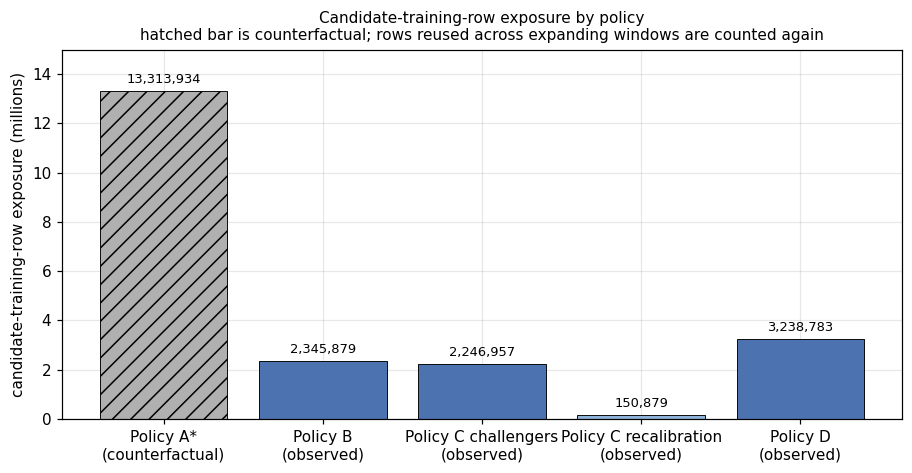

In [14]:
# Plot candidate training-row exposure by policy
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})

fig1_labels = ["Policy A*\n(counterfactual)", "Policy B\n(observed)", "Policy C challengers\n(observed)", "Policy C recalibration\n(observed)", "Policy D\n(observed)"]
fig1_values = [a_star_exposure, b_exposure,
               int(w.loc["Policy C", "challenger_training_row_exposure"]),
               int(w.loc["Policy C", "recalibration_training_row_exposure"]),
               int(w.loc["Policy D", "challenger_training_row_exposure"])]

fig, ax = plt.subplots(figsize=(8.4, 4.4))
bars = ax.bar(fig1_labels, np.array(fig1_values) / 1e6, color=["#b0b0b0", "#4c72b0", "#4c72b0", "#8fb3d9", "#4c72b0"], edgecolor="black", linewidth=0.6)
bars[0].set_hatch("//")
for bar, value in zip(bars, fig1_values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2, f"{value:,.0f}", ha="center", va="bottom", fontsize=8.5)
ax.set_ylabel("candidate-training-row exposure (millions)")
ax.set_title("Candidate-training-row exposure by policy\nhatched bar is counterfactual; rows reused across expanding windows are counted again", fontsize=10)
ax.set_ylim(0, 15)
plt.tight_layout()
plt.savefig(OUTPUTS / "fig_candidate_row_exposure.png", bbox_inches="tight")
plt.show()

## 5. Measured Policy C Google Cloud replay workload

Policy C is the only policy with measured Cloud Run runtime. Policy A ran alongside it as a request-only shadow baseline, while Policies B and D remained offline comparators.

The replay contains 41 main monthly executions: 36 scoring months and five tail decision months. Two additional runs were recorded as `duplicate_run_skipped` and are excluded from the runtime totals.

In [15]:
# Load the Cloud Run replay records and set aside the duplicate runs
prototype_runs = cba.prepare_prototype_runs(GCP / "prototype_runs.json")
main_runs, duplicate_runs = cba.split_main_and_duplicate_runs(prototype_runs)
display(prototype_runs["outcome"].value_counts().rename_axis("outcome").to_frame("records"))
print(f"raw records {len(prototype_runs)}   main replay {len(main_runs)}   duplicate_run_skipped {len(duplicate_runs)} ({', '.join(duplicate_runs['decision_month'])})")

check("GCP raw prototype records", len(prototype_runs), 43)
check("main replay executions", len(main_runs), 41)
check("duplicate_run_skipped records", len(duplicate_runs), 2)

,records
outcome,
completed,36
no_decision,5
duplicate_run_skipped,2


raw records 43   main replay 41   duplicate_run_skipped 2 (2015-11, 2015-11)


True

In [16]:
# Summarise the main replay runtime and execution categories
main_runs = main_runs.copy()
main_runs["category"] = main_runs.apply(cba.classify_execution, axis=1)
main_runs["is_scoring_month"] = main_runs["rows_scored"] > 0

runtime_summary = cba.summarise_cloud_runtime(main_runs)
for key, value in runtime_summary.items():
    print(f"{key:32s}: {value:,.6f}" if isinstance(value, float) else f"{key:32s}: {value:,}")

display(main_runs.groupby(["category", "is_scoring_month"]).agg(executions=("run_id", "count"),
                                                               total_seconds=("job_duration_seconds", "sum"),
                                                               mean_seconds=("job_duration_seconds", "mean")).round(2).reset_index())

check("scoring executions", runtime_summary["scoring_executions"], 36)
check("tail (no-scoring) executions", runtime_summary["tail_executions"], 5)
check("total main replay runtime (s)", runtime_summary["total_wall_clock_seconds"], 1625.4, tolerance=0.05)
check("cumulative monitoring duration (s)", runtime_summary["total_monitoring_seconds"], 493.981456, tolerance=1e-4)
check("cumulative candidate-fit duration (s)", runtime_summary["total_candidate_fit_seconds"], 77.901785, tolerance=1e-4)

main_executions                 : 41
scoring_executions              : 36
tail_executions                 : 5
total_wall_clock_seconds        : 1,625.400000
mean_wall_clock_seconds         : 39.643902
median_wall_clock_seconds       : 38.600000
min_wall_clock_seconds          : 23.720000
max_wall_clock_seconds          : 75.310000
total_monitoring_seconds        : 493.981456
total_candidate_fit_seconds     : 77.901785
total_rows_scored               : 1,041,560


,category,is_scoring_month,executions,total_seconds,mean_seconds
0,candidate-fit month,False,1,64.52,64.52
1,candidate-fit month,True,4,238.3,59.58
2,"early month, no decision yet",True,5,137.49,27.5
3,maturity-only tail month,False,4,104.77,26.19
4,"monitoring and decision, no candidate fit",True,27,1080.32,40.01


True

The 41 main executions took 1,625.40 seconds in total. Monitoring accounted for 493.98 seconds and candidate fitting for 77.90 seconds.
These component timers are only part of the total job runtime. The remaining time includes scoring, data loading, delayed-evidence processing, Cloud Storage and BigQuery operations, and container overhead.

In [17]:
# Cross-check against the Cloud Run platform execution list
cloud_executions = cba.summarise_cloud_run_executions(GCP / "executions.json")
succeeded_executions = int(cloud_executions["succeeded"].sum())
print(f"platform executions listed {len(cloud_executions)}   succeeded {succeeded_executions}   failed {int((~cloud_executions['succeeded']).sum())}")
display(cloud_executions.loc[~cloud_executions["succeeded"], ["execution_name", "created_at", "completion_time", "failed_count"]])

check("succeeded Cloud Run executions match application records", succeeded_executions, len(prototype_runs),
      note="43 application audit records against 43 successful platform executions")

platform executions listed 44   succeeded 43   failed 1


,execution_name,created_at,completion_time,failed_count
0,monitor-and-decide-dphln,2026-08-04T22:03:31.201466Z,2026-08-04T22:04:39.488835Z,1


True

The Cloud Run platform export lists 44 executions: 43 successful and one failed. The 43 successful executions match the 43 application audit records. The failed execution occurred before the replay sequence and produced no application record.

Cloud promotion outcomes are taken from `candidate_attempts.json` and `policy_decisions.json`, which agree on the promotion results.

In [18]:
# Join cloud candidate fits to measured runtimes
cloud_attempts = cba.load_gcp_table(GCP / "candidate_attempts.json")
for column in ("total_training_rows", "historical_training_rows", "simulation_training_rows"):
    cloud_attempts[column] = pd.to_numeric(cloud_attempts[column])

fit_runs = main_runs.loc[main_runs["candidate_fit_started"], ["decision_month", "candidate_type", "candidate_fit_duration_seconds",
                                                              "candidate_promoted", "job_duration_seconds", "rows_scored", "run_id"]]

# validate fails the join rather than silently duplicating or dropping a fit
candidate_fit_runtime = cloud_attempts.merge(fit_runs, on=["decision_month", "candidate_type"], how="inner", validate="one_to_one").sort_values("decision_month").reset_index(drop=True)
candidate_fit_runtime["in_stream"] = candidate_fit_runtime["decision_month"] <= last_scoring_month

display(candidate_fit_runtime[["decision_month", "candidate_type", "total_training_rows", "candidate_fit_duration_seconds",
                               "deployment_gate_passed", "failed_criteria", "in_stream", "job_duration_seconds"]])
check("cloud candidate fits", len(candidate_fit_runtime), 5)

,decision_month,candidate_type,total_training_rows,candidate_fit_duration_seconds,deployment_gate_passed,failed_criteria,in_stream,job_duration_seconds
0,2014-11,challenger,182224,5.5963,false,calibration_gap,True,45.86
1,2015-04,recalibration,150879,1.316631,true,none,True,54.31
2,2015-11,challenger,454608,13.480607,true,none,True,62.82
3,2016-05,challenger,651696,24.72868,true,none,True,75.31
4,2017-01,challenger,958429,32.779568,true,none,False,64.52


True

In [19]:
# Check the measured fit values used in the dissertation
expected_fits = {("2014-11", "challenger"): (182_224, 5.5963), ("2015-04", "recalibration"): (150_879, 1.3166),
                 ("2015-11", "challenger"): (454_608, 13.4806), ("2016-05", "challenger"): (651_696, 24.7287),
                 ("2017-01", "challenger"): (958_429, 32.7796)}
indexed = candidate_fit_runtime.set_index(["decision_month", "candidate_type"])

for key, (rows_expected, seconds_expected) in expected_fits.items():
    check(f"{key[0]} {key[1]} training rows", int(indexed.loc[key, "total_training_rows"]), rows_expected)
    check(f"{key[0]} {key[1]} measured fit seconds", float(indexed.loc[key, "candidate_fit_duration_seconds"]), seconds_expected, tolerance=5e-4)

Challenger fit time increased with training-window size, from 5.60 seconds for 182,224 rows in November 2014 to 32.78 seconds for 958,429 rows in January 2017.

The April 2015 recalibration is treated separately because it only refits the probability mapping. It used 150,879 rows and took 1.32 seconds. The November 2014 challenger was rejected by the deployment gate, but its 5.60 seconds of fitting work was still incurred.

In [20]:
# Read the Cloud Run resource allocation from the Job definition
allocation = cba.read_cloud_run_allocation(GCP / "monitor-and-decide.yaml")
display(pd.DataFrame([allocation]).T.rename(columns={0: "value"}))
check("Cloud Run vCPU allocation", allocation["cpu_allocated"], 4.0)
check("Cloud Run memory allocation (GiB)", allocation["memory_allocated_gib"], 16.0)

# Allocation-time proxies: elapsed time x configured allocation
replay_proxy = cba.allocation_time_proxy(runtime_summary["total_wall_clock_seconds"], allocation["cpu_allocated"], allocation["memory_allocated_gib"])
fit_proxy = cba.allocation_time_proxy(runtime_summary["total_candidate_fit_seconds"], allocation["cpu_allocated"], allocation["memory_allocated_gib"])
display(pd.DataFrame([{"scope": "41-month main replay", **replay_proxy},
                      {"scope": "candidate fitting only (share of the above)", **fit_proxy}]).round(4))

,value
job_name,monitor-and-decide
region,europe-west2
cpu_allocated,4.0
memory_allocated_raw,16Gi
memory_allocated_gib,16.0
task_count,1
max_retries,0


,scope,wall_clock_seconds,vcpu_seconds,vcpu_hours,gib_seconds,gib_hours
0,41-month main replay,1625.4000,6501.6000,1.8060,26006.4000,7.2240
1,candidate fitting only (share of the above),77.9018,311.6071,0.0866,1246.4286,0.3462


The Cloud Run job used 4 vCPUs and 16 GiB of memory. Across the main replay, this corresponds to 1.81 vCPU-hours and 7.22 GiB-hours of allocated resource time.

These are allocation-time proxies rather than utilisation measures. The candidate-fitting values are a subset of the same replay allocation, not additional resource use.

## 6. Challenger Training Rows and Measured Fit Runtime

Only the four challenger fits are used for this comparison. The recalibration is excluded because it is a different fitting procedure.

With only four observations, the fitted models are descriptive rather than general estimates of challenger runtime.

In [21]:
# Fit the descriptive challenger runtime models
challenger_fits = candidate_fit_runtime.loc[candidate_fit_runtime["candidate_type"] == "challenger"].sort_values("total_training_rows")
x_million = challenger_fits["total_training_rows"].to_numpy() / 1_000_000.0
y_seconds = challenger_fits["candidate_fit_duration_seconds"].to_numpy()

linear_model = cba.fit_linear_model(x_million, y_seconds)
origin_model = cba.fit_through_origin_model(x_million, y_seconds)
runtime_scaling_model = pd.DataFrame([linear_model, origin_model])
display(runtime_scaling_model.round(6))

check("linear model intercept", round(linear_model["intercept"], 3), -1.260, tolerance=0.002)
check("linear model slope", round(linear_model["slope"], 3), 36.327, tolerance=0.002)
check("linear model R squared", round(linear_model["r_squared"], 4), 0.9788, tolerance=0.0002)
check("through-origin slope", round(origin_model["slope"], 3), 34.539, tolerance=0.002)
check("through-origin R squared", round(origin_model["r_squared"], 4), 0.9758, tolerance=0.0002)

,specification,intercept,slope,r_squared,n_observations
0,seconds ~ intercept + slope * million_rows,-1.260187,36.327309,0.978823,4
1,seconds ~ slope * million_rows (through origin),0.000000,34.538752,0.975847,4


True

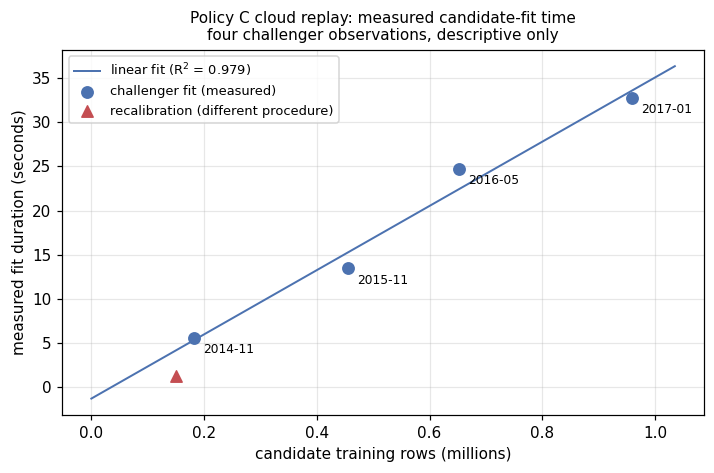

In [22]:
# Plot measured challenger fit time against training rows
fig, ax = plt.subplots(figsize=(6.6, 4.4))
grid = np.linspace(0, x_million.max() * 1.08, 100)
ax.plot(grid, linear_model["intercept"] + linear_model["slope"] * grid, color="#4c72b0", linewidth=1.3, label=f"linear fit (R$^2$ = {linear_model['r_squared']:.3f})")
ax.scatter(x_million, y_seconds, s=55, color="#4c72b0", zorder=3, label="challenger fit (measured)")

recalibration = candidate_fit_runtime.loc[candidate_fit_runtime["candidate_type"] == "recalibration"]
ax.scatter(recalibration["total_training_rows"] / 1e6, recalibration["candidate_fit_duration_seconds"], s=55, marker="^", color="#c44e52", zorder=3, label="recalibration (different procedure)")

for _, row in challenger_fits.iterrows():
    ax.annotate(row["decision_month"], (row["total_training_rows"] / 1e6, row["candidate_fit_duration_seconds"]), textcoords="offset points", xytext=(6, -10), fontsize=8)

ax.set_xlabel("candidate training rows (millions)")
ax.set_ylabel("measured fit duration (seconds)")
ax.set_title("Policy C cloud replay: measured candidate-fit time\nfour challenger observations, descriptive only", fontsize=10)
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUTS / "fig_challenger_fit_scaling.png", bbox_inches="tight")
plt.show()

Challenger fit time increased with training-window size. The linear model gives a slope of about 36.33 seconds per million rows with \(R^2 = 0.979\).

Its intercept is slightly negative, so the through-origin model is also reported. Both fits are based on only four Policy C challenger observations and are used only for the runtime counterfactuals that follow.

## 7. Modelled Runtime for Policy B and Policy A*

Neither Policy B nor Policy A* was replayed on Cloud Run, so these runtimes are modelled rather than measured. The Section 6 challenger-runtime relationships are applied to their respective training-window sizes.

The row-exposure comparison from Section 4 remains the primary computational-burden result.

In [23]:
# Estimate modelled runtimes for Policy B and A*
policy_b_rows = attempts["B"]["total_training_rows"].to_numpy()
policy_a_star_rows = feasible["total_training_rows"].to_numpy()

modelled = []
for name, model in (("linear (with intercept)", linear_model), ("through origin", origin_model)):
    b_pred, a_pred = cba.predict_runtime(model, policy_b_rows), cba.predict_runtime(model, policy_a_star_rows)
    modelled.append({"model_specification": name, "policy_B_modelled_seconds": float(b_pred.sum()), "policy_B_fits": int(len(b_pred)),
                     "policy_A_star_modelled_seconds": float(a_pred.sum()), "policy_A_star_fits": int(len(a_pred)),
                     "modelled_reduction_A_star_to_B_pct": float(cba.percentage_reduction(a_pred.sum(), b_pred.sum()))})

modelled_runtime = pd.DataFrame(modelled)
display(modelled_runtime.round(3))

,model_specification,policy_B_modelled_seconds,policy_B_fits,policy_A_star_modelled_seconds,policy_A_star_fits,modelled_reduction_A_star_to_B_pct
0,linear (with intercept),78.919,5,449.634,27,82.448
1,through origin,81.024,5,459.847,27,82.380


In [24]:
# Show modelled runtime for each fit
b_predictions = pd.DataFrame({"decision_month": attempts["B"]["decision_month"],
                              "training_rows": policy_b_rows,
                              "modelled_seconds_linear": cba.predict_runtime(linear_model, policy_b_rows),
                              "modelled_seconds_origin": cba.predict_runtime(origin_model, policy_b_rows)})
display(b_predictions.round(3))

a_star_predictions = feasible[["request_month", "total_training_rows"]].copy()
a_star_predictions["modelled_seconds_linear"] = cba.predict_runtime(linear_model, a_star_predictions["total_training_rows"])
a_star_predictions["modelled_seconds_origin"] = cba.predict_runtime(origin_model, a_star_predictions["total_training_rows"])
display(pd.concat([a_star_predictions.head(3), a_star_predictions.tail(2)]).round(3))   # 27 fits; first and last shown

,decision_month,training_rows,modelled_seconds_linear,modelled_seconds_origin
0,2014-10,165711,4.760,5.723
1,2015-04,285693,9.118,9.867
2,2015-10,429247,14.333,14.826
3,2016-04,625009,21.445,21.587
4,2016-10,840219,29.263,29.020


,request_month,total_training_rows,modelled_seconds_linear,modelled_seconds_origin
6,2014-10,165711,4.760,5.723
7,2014-11,182224,5.360,6.294
8,2014-12,201295,6.052,6.952
31,2016-11,897777,31.354,31.008
32,2016-12,931941,32.595,32.188


## 8. Dissertation and Appendix Tables

The tables below collect the main computational-burden results used in the dissertation appendix. Full-precision values are saved to CSV, while displayed values are rounded where appropriate.

For Policy C, challenger row exposure excludes the separate recalibration fit.

In [25]:
# Build Appendix Table H1
table_h1 = pd.DataFrame([{"Policy": "A", "Feature-drift requests": n_requests, "Candidate evaluations": 0, "Candidate fits": 0,
                          "Challenger fits": 0, "Recalibrations": 0, "Challenger row exposure": 0,
                          "Status of evidence": "Observed, request stage only — no candidate was fitted"},
                         {"Policy": "A*", "Feature-drift requests": n_requests, "Candidate evaluations": pd.NA, "Candidate fits": a_star_fits,
                          "Challenger fits": a_star_fits, "Recalibrations": 0, "Challenger row exposure": a_star_exposure,
                          "Status of evidence": "COUNTERFACTUAL — reconstructed workload, never executed"},
                         {"Policy": "B", "Feature-drift requests": b_counts["raw candidate triggers"], "Candidate evaluations": evaluation_counts["B"],
                          "Candidate fits": 5, "Challenger fits": 5, "Recalibrations": 0, "Challenger row exposure": b_exposure,
                          "Status of evidence": "Observed offline"},
                         {"Policy": "C", "Feature-drift requests": pd.NA, "Candidate evaluations": evaluation_counts["C"],
                          "Candidate fits": 5, "Challenger fits": 4, "Recalibrations": 1,
                          "Challenger row exposure": int(w.loc["Policy C", "challenger_training_row_exposure"]),
                          "Status of evidence": "Observed offline and replayed on Cloud Run"},
                         {"Policy": "D", "Feature-drift requests": pd.NA, "Candidate evaluations": evaluation_counts["D"],
                          "Candidate fits": 6, "Challenger fits": 6, "Recalibrations": 0,
                          "Challenger row exposure": int(w.loc["Policy D", "challenger_training_row_exposure"]),
                          "Status of evidence": "Observed offline"}])
display(table_h1)
table_h1.to_csv(OUTPUTS / "table_H1_candidate_fitting_workload.csv", index=False)

,Policy,Feature-drift requests,Candidate evaluations,Candidate fits,Challenger fits,Recalibrations,Challenger row exposure,Status of evidence
0,A,33,0,0,0,0,0,"Observed, request stage only — no candidate wa..."
1,A*,33,<NA>,27,27,0,13313934,"COUNTERFACTUAL — reconstructed workload, never..."
2,B,33,5,5,5,0,2345879,Observed offline
3,C,<NA>,5,5,4,1,2246957,Observed offline and replayed on Cloud Run
4,D,<NA>,6,6,6,0,3238783,Observed offline


In [26]:
# Build Appendix Table H2
table_h2 = candidate_fit_runtime[["decision_month", "candidate_type", "total_training_rows", "candidate_fit_duration_seconds",
                                  "deployment_gate_passed", "failed_criteria", "in_stream"]].rename(
    columns={"decision_month": "Decision month", "candidate_type": "Action", "total_training_rows": "Training rows",
             "candidate_fit_duration_seconds": "Measured fit time (s)", "deployment_gate_passed": "Gate outcome",
             "failed_criteria": "Failed criterion", "in_stream": "In-stream (within scoring period)"})
table_h2["Measured fit time (s)"] = table_h2["Measured fit time (s)"].round(4)
display(table_h2)
table_h2.to_csv(OUTPUTS / "table_H2_measured_cloud_candidate_fits.csv", index=False)

,Decision month,Action,Training rows,Measured fit time (s),Gate outcome,Failed criterion,In-stream (within scoring period)
0,2014-11,challenger,182224,5.5963,false,calibration_gap,True
1,2015-04,recalibration,150879,1.3166,true,none,True
2,2015-11,challenger,454608,13.4806,true,none,True
3,2016-05,challenger,651696,24.7287,true,none,True
4,2017-01,challenger,958429,32.7796,true,none,False


In [27]:
# Build Appendix Table H3
table_h3 = pd.DataFrame([("Main replay executions", f"{runtime_summary['main_executions']}"),
                         ("Scoring executions", f"{runtime_summary['scoring_executions']}"),
                         ("Tail executions (no new scoring)", f"{runtime_summary['tail_executions']}"),
                         ("Duplicate-run records excluded", f"{len(duplicate_runs)}"),
                         ("Total wall-clock runtime (s)", f"{runtime_summary['total_wall_clock_seconds']:.2f}"),
                         ("Mean wall-clock runtime (s)", f"{runtime_summary['mean_wall_clock_seconds']:.2f}"),
                         ("Median wall-clock runtime (s)", f"{runtime_summary['median_wall_clock_seconds']:.2f}"),
                         ("Total recorded monitoring time (s)", f"{runtime_summary['total_monitoring_seconds']:.2f}"),
                         ("Total recorded candidate-fit time (s)", f"{runtime_summary['total_candidate_fit_seconds']:.2f}"),
                         ("Cloud Run CPU allocation", f"{allocation['cpu_allocated']:.0f} vCPU"),
                         ("Cloud Run memory allocation", f"{allocation['memory_allocated_gib']:.0f} GiB"),
                         ("vCPU-hour allocation proxy", f"{replay_proxy['vcpu_hours']:.3f}"),
                         ("GiB-hour allocation proxy", f"{replay_proxy['gib_hours']:.3f}"),
                         ("Monetary cost", "not calculated — no validated billing export in the evidence bundle")],
                        columns=["Measure", "Value"])
display(table_h3)
table_h3.to_csv(OUTPUTS / "table_H3_cloud_replay_summary.csv", index=False)

,Measure,Value
0,Main replay executions,41
1,Scoring executions,36
2,Tail executions (no new scoring),5
3,Duplicate-run records excluded,2
4,Total wall-clock runtime (s),1625.40
5,Mean wall-clock runtime (s),39.64
6,Median wall-clock runtime (s),38.60
7,Total recorded monitoring time (s),493.98
8,Total recorded candidate-fit time (s),77.90
9,Cloud Run CPU allocation,4 vCPU


In [28]:
# Build Appendix Table H4
table_h4 = pd.DataFrame([{"Comparison": "A* versus B (challenger row exposure)",
                          "Result": f"{a_star_exposure:,} to {b_exposure:,} rows ({row_reduction_pct:.1f}% lower)",
                          "Reading": "Cooldown and label-availability constraints cut the fitting work the same feature-drift signal would otherwise have generated. A* is counterfactual."},
                         {"Comparison": "B versus C (candidate fitting)", "Result": "5 fits each",
                          "Reading": "No computational saving of C over B. The difference is in trigger selectivity, action choice and rejection, not fitting volume."},
                         {"Comparison": "C action composition",
                          "Result": "4 challengers, 1 recalibration, 1 rejection, 3 in-stream promotions (+1 tail promotion in January 2017)",
                          "Reading": "The policy chose between a light and a heavy intervention and declined to deploy one candidate it had already fitted. The January 2017 promotion had no subsequent scoring exposure."},
                         {"Comparison": "D calendar workload",
                          "Result": f"6 scheduled fits, {int(w.loc['Policy D', 'challenger_training_row_exposure']):,} rows",
                          "Reading": "A fixed six-month calendar fitted more candidates and processed more rows than either drift-driven governed policy."},
                         {"Comparison": "Measured cloud burden (Policy C only)",
                          "Result": f"{runtime_summary['total_wall_clock_seconds']:.1f} s across 41 executions; {runtime_summary['total_candidate_fit_seconds']:.1f} s of that in candidate fitting",
                          "Reading": "Candidate fitting was a small share of total replay time. Policies A, B and D have no measured cloud runtime."}])
display(table_h4)
table_h4.to_csv(OUTPUTS / "table_H4_workload_interpretation.csv", index=False)

,Comparison,Result,Reading
0,A* versus B (challenger row exposure),"13,313,934 to 2,345,879 rows (82.4% lower)",Cooldown and label-availability constraints cu...
1,B versus C (candidate fitting),5 fits each,No computational saving of C over B. The diffe...
2,C action composition,"4 challengers, 1 recalibration, 1 rejection, 3...",The policy chose between a light and a heavy i...
3,D calendar workload,"6 scheduled fits, 3,238,783 rows",A fixed six-month calendar fitted more candida...
4,Measured cloud burden (Policy C only),1625.4 s across 41 executions; 77.9 s of that ...,Candidate fitting was a small share of total r...


In [29]:
# Save the supporting reproducibility tables
cloud_runtime_summary = pd.DataFrame([{**runtime_summary, "duplicate_run_skipped_records": int(len(duplicate_runs)),
                                       "raw_prototype_records": int(len(prototype_runs)),
                                       "cloud_run_executions_listed": int(len(cloud_executions)),
                                       "cloud_run_executions_succeeded": succeeded_executions,
                                       "cloud_run_executions_failed": int((~cloud_executions["succeeded"]).sum()),
                                       "cpu_allocated": allocation["cpu_allocated"], "memory_allocated_gib": allocation["memory_allocated_gib"],
                                       "replay_vcpu_hours_allocation_proxy": replay_proxy["vcpu_hours"],
                                       "replay_gib_hours_allocation_proxy": replay_proxy["gib_hours"],
                                       "candidate_fit_vcpu_hours_allocation_proxy": fit_proxy["vcpu_hours"],
                                       "candidate_fit_gib_hours_allocation_proxy": fit_proxy["gib_hours"]}])

cloud_execution_detail = main_runs[["decision_month", "outcome", "category", "is_scoring_month", "rows_scored",
                                    "job_duration_seconds", "monitoring_duration_seconds", "candidate_fit_duration_seconds",
                                    "candidate_fit_started", "candidate_type", "candidate_promoted",
                                    "cpu", "memory", "run_id", "started_at", "ended_at"]].sort_values("decision_month").reset_index(drop=True)

burden_columns = ["source", "policy", "decision_month", "candidate_type", "historical_training_rows", "simulation_training_rows", "total_training_rows"]
policy_training_row_burden = pd.concat([fit_detail.assign(source="observed candidate fit").rename(columns={"policy_label": "policy"})[burden_columns],
                                        feasible.assign(source="A* counterfactual fit", policy="Policy A*", candidate_type="challenger (counterfactual)").rename(columns={"request_month": "decision_month"})[burden_columns]],
                                       ignore_index=True)

outputs_written = {"cloud_runtime_summary.csv": cloud_runtime_summary,
                   "cloud_execution_detail.csv": cloud_execution_detail,
                   "candidate_fit_runtime.csv": candidate_fit_runtime,
                   "policy_A_counterfactual_fits.csv": policy_a_star,
                   "policy_training_row_burden.csv": policy_training_row_burden,
                   "policy_workload_summary.csv": policy_workload_summary,
                   "runtime_scaling_model.csv": pd.concat([runtime_scaling_model, modelled_runtime], axis=1)}

for filename, frame in outputs_written.items():
    frame.to_csv(OUTPUTS / filename, index=False)
    print(f"wrote {filename:38s} rows={len(frame)}")

wrote cloud_runtime_summary.csv              rows=1
wrote cloud_execution_detail.csv             rows=41
wrote candidate_fit_runtime.csv              rows=5
wrote policy_A_counterfactual_fits.csv       rows=33
wrote policy_training_row_burden.csv         rows=43
wrote policy_workload_summary.csv            rows=5
wrote runtime_scaling_model.csv              rows=2


In [30]:
# Save the computational-burden metadata
metadata_record = {"notebook": "06_computational_burden",
                   "generated_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                   "project_root": str(BASE),
                   "input_file_counts": {"offline": n_offline, "gcp": n_gcp, "total": len(inventory)},
                   "study_configuration": {"label_delay_months": config.label_delay_months,
                                           "validation_window_months": config.validation_window_months,
                                           "deployment_cooldown_months": config.deployment_cooldown_months,
                                           "candidate_evaluation_holdoff_months": config.candidate_evaluation_holdoff_months,
                                           "scoring_cohorts": int(len(monthly_counts)),
                                           "first_scoring_month": first_scoring_month, "last_scoring_month": last_scoring_month,
                                           "historical_training_rows": historical_rows},
                   "offline_workload": offline_workload.to_dict(orient="records"),
                   "policy_a_counterfactual": {"requests": int(n_requests), "feasible_fits": int(a_star_fits),
                                               "infeasible_requests": int(len(infeasible)), "infeasible_months": infeasible["request_month"].tolist(),
                                               "challenger_training_row_exposure": int(a_star_exposure),
                                               "reduction_to_policy_b_pct": float(row_reduction_pct)},
                   "gcp_replay": {"project": "YOUR_GCP_PROJECT", "region": allocation["region"], "cloud_run_job": allocation["job_name"],
                                  "policy_version": "v1_primary_gate_delay5_cloud",
                                  "raw_prototype_records": int(len(prototype_runs)),
                                  "main_replay_executions": int(runtime_summary["main_executions"]),
                                  "duplicate_run_skipped": int(len(duplicate_runs)),
                                  "scoring_executions": int(runtime_summary["scoring_executions"]),
                                  "tail_executions": int(runtime_summary["tail_executions"]),
                                  "cloud_run_executions_listed": int(len(cloud_executions)),
                                  "cloud_run_executions_succeeded": int(succeeded_executions),
                                  "total_wall_clock_seconds": runtime_summary["total_wall_clock_seconds"],
                                  "total_monitoring_seconds": runtime_summary["total_monitoring_seconds"],
                                  "total_candidate_fit_seconds": runtime_summary["total_candidate_fit_seconds"],
                                  "cpu_allocated": allocation["cpu_allocated"], "memory_allocated_gib": allocation["memory_allocated_gib"],
                                  "allocation_time_proxy_replay": replay_proxy, "allocation_time_proxy_candidate_fitting": fit_proxy},
                   "runtime_model": {"principal": linear_model, "through_origin": origin_model,
                                     "modelled_totals": modelled_runtime.to_dict(orient="records"),
                                     "fitted_on": "four measured Policy C cloud challenger fits; recalibration excluded"},
                   "warnings": ["No monetary cost was calculated: no validated Cloud Billing export exists in the evidence bundle.",
                                "vCPU-seconds and GiB-seconds are allocation-time proxies from the configured Cloud Run limits, not measured utilisation.",
                                "Policies A, B and D were not replayed on Cloud Run; their runtime figures are modelled.",
                                "Policy A is request-stage only and fitted no candidates. Policy A* is a counterfactual.",
                                "Policy B and Policy C each fitted five candidates, so no computational saving of C over B is claimed.",
                                "The runtime-scaling relationship rests on four challenger observations under one Cloud Run configuration.",
                                "The five-month label delay is a simulation assumption, not Lending Club's true label-maturity timing."]}

with (OUTPUTS / "computational_burden_metadata.json").open("w") as fh:
    json.dump(metadata_record, fh, indent=2)

print("wrote computational_burden_metadata.json")

wrote computational_burden_metadata.json
